# Compare a generated run with the reference report

`EDA_Report.ipynb` answers the research question by hand (7 of 7 facts correct). This notebook puts one run of the
local model next to it: its values, its method, its plots, its report text, and what the reflection levels changed.

It only **reads** what a run left behind (`code.py`, `stdout.txt`, `outputs/`, `result.json`) and never executes the
generated code. The scores are computed with the same functions as `analyze.py` (`src/checker.py`, `src/evaluate.py`),
so they match `PERFORMANCE_LOG.md`.

Run it from the project folder with the `.venv` kernel. Choose the run in the next cell.

In [1]:
EXP = "E10_baseline_v3"   # any experiment: a baseline or a reflection level
SEED = 105
VERSION = None            # None = the version this experiment produced (v1 for a baseline, 2a/2b/2c for a level)

## 0. Setup

In [2]:
import base64
import difflib
import html
import json
import re
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent   # started from notebooks/ or from the project folder
assert (ROOT / "experiments").exists(), f"experiments/ not found below {ROOT}"
sys.path.insert(0, str(ROOT))

from src.checker import GT, GT_NUMS, KEYS, extract_results, numbers_in
from src.evaluate import FUNNEL, facts_for_dir, funnel_for_dir, report_quality_for_dir, text_claims

EXP_DIR = ROOT / "experiments"
CSV_COLUMNS = pd.read_csv(ROOT / "data" / "stix_flarelist.csv", nrows=0).columns.tolist()
OK, NO = "✓", "✗"


def manifest(exp):
    return json.loads((EXP_DIR / exp / "experiment.json").read_text(encoding="utf-8"))


def version_dir(exp, seed, version=None):
    """Folder of one version. Without a version: the one the experiment produced (not a copied v1)."""
    case = EXP_DIR / exp / "cases" / f"s{seed}"
    if version:
        return case / version
    own = [d for d in sorted(case.iterdir()) if d.is_dir() and (d / "result.json").exists()]
    return ([d for d in own if d.name != "v1"] or own)[-1]


def read(d, name):
    p = Path(d) / name
    return p.read_text(encoding="utf-8", errors="replace") if p.exists() else ""


def fmt(v):
    if v is None:
        return "–"
    if isinstance(v, dict):
        return ", ".join(f"{str(k)[:4]}: {fmt(x)}" for k, x in v.items())
    if isinstance(v, float):
        return f"{v:.4g}"
    return str(v)


def mark(ok):
    return "–" if ok is None else (OK if ok else NO)

## 1. All seeds of the experiment
Pick an interesting seed for the sections below. `depth` = funnel stages passed in a row (0-8), `facts` = share of the
7 values that match the ground truth, `report` = report quality (0-1).

In [3]:
m = manifest(EXP)
display(Markdown(f"**{EXP}** · level `{m.get('level')}` · base `{m.get('base') or '–'}` · data `{m.get('data_context')}` "
                 f"· shims `{m.get('runner_shims')}` · model `{m.get('model')}` T={m.get('temperature')}  \n"
                 f"What changed: {m.get('change') or '–'}"))
rows = []
for case in sorted((EXP_DIR / EXP / "cases").glob("s*")):
    d = version_dir(EXP, int(case.name[1:]))
    r = json.loads(read(d, "result.json"))
    f, fn, rq = facts_for_dir(d), funnel_for_dir(d), report_quality_for_dir(d)
    rows.append({"seed": int(case.name[1:]), "version": d.name, "exit": r.get("exit_code"),
                 "error": r.get("error_category") or "", "depth": f"{fn['depth']}/{len(FUNNEL)}",
                 "facts": f"{f['fact_score']:.0%}", "report": rq["overall"], "plots": r.get("n_plots"),
                 "flags": len(rq["flags"])})
pd.DataFrame(rows).set_index("seed")

**E10_baseline_v3** · level `baseline` · base `–` · data `schema` · shims `True` · model `qwen3-4b-instruct-16k` T=0.7  
What changed: baseline v3: results saved to /outputs/results.json

,version,exit,error,depth,facts,report,plots,flags
seed,,,,,,,,
101,v1,0,,7/8,43%,0.701,2,7
102,v1,0,,7/8,71%,0.753,2,5
103,v1,1,other:IndexError,2/8,0%,0.158,0,4
104,v1,1,datetime_type,2/8,0%,0.110,0,7
105,v1,0,,7/8,71%,0.702,2,7


## 2. The selected run

In [4]:
D = version_dir(EXP, SEED, VERSION)
R = json.loads(read(D, "result.json"))
CODE, STDOUT, STDERR = read(D, "code.py"), read(D, "stdout.txt"), read(D, "stderr.txt")
FACTS, FN, RQ = facts_for_dir(D), funnel_for_dir(D), report_quality_for_dir(D)
MODEL = extract_results(STDOUT, D / "outputs") or {}
cost = R.get("cost") or {}

source = ("outputs/results.json" if (D / "outputs" / "results.json").exists()
          else "RESULTS_JSON line in stdout" if MODEL else "none (no readable results)")
display(Markdown(
    f"**{D.relative_to(ROOT)}**  \n"
    f"exit code `{R.get('exit_code')}`" + (f" · error `{R.get('error_category')}`: {R.get('error_message')}" if R.get("error_category") else "")
    + f"  \nresults read from: {source}  \n"
    f"funnel: " + " → ".join(f"{s} {mark(ok)}" for s, ok in FN["stages"].items()) + f"  (depth {FN['depth']}/{len(FUNNEL)})  \n"
    f"cost: {cost.get('llm_calls')} LLM call(s), {cost.get('prompt_tokens')} + {cost.get('completion_tokens')} tokens, "
    f"{cost.get('llm_seconds')} s LLM, {cost.get('exec_seconds')} s execution"))
if STDERR.strip() and R.get("exit_code") not in (0, None):
    display(HTML("<pre style='max-height:16em;overflow:auto'>" + html.escape("\n".join(STDERR.splitlines()[-12:])) + "</pre>"))

**experiments/E10_baseline_v3/cases/s105/v1**  
exit code `0`  
results read from: outputs/results.json  
funnel: answered ✓ → code_found ✓ → ran ✓ → json_found ✓ → json_strict ✓ → keys_complete ✓ → any_fact ✓ → all_facts ✗  (depth 7/8)  
cost: 1 LLM call(s), 1356 + 1654 tokens, 261.5 s LLM, 6.9 s execution

## 3. Facts: model vs ground truth
The ground truth (`ground_truth.json`, computed independently by `step0/facts.py`) gives the same values as
`EDA_Report.ipynb`. The note column says *why* a value differs, where that can be seen from the value itself.

In [5]:
def note(key, val, truth, ok):
    if ok or val is None:
        return "" if ok else "missing"
    notes = []
    if isinstance(truth, dict) and isinstance(val, dict):
        mine, real = {str(k)[:4] for k in val}, set(truth)
        if real - mine:
            notes.append("years missing: " + ", ".join(sorted(real - mine)))
        if mine - real:
            notes.append("extra years: " + ", ".join(sorted(mine - real)))
        nums = [x for x in val.values() if isinstance(x, (int, float)) and not isinstance(x, bool)]
        if key.startswith("pct") and nums and max(nums) <= 1:
            notes.append("fractions (0-1), not percent")
    elif isinstance(truth, (int, float)) and not isinstance(truth, bool) and isinstance(val, (int, float)) and truth:
        notes.append(f"{val / truth:.2g} x the true value")
    return "; ".join(notes)


facts = pd.DataFrame([{"fact": k, "model": fmt(MODEL.get(k)), "ground truth": fmt(GT.get(gk)),
                       "ok": mark(FACTS["checks"].get(k)), "note": note(k, MODEL.get(k), GT.get(gk), FACTS["checks"].get(k))}
                      for k, gk in KEYS.items()]).set_index("fact")
display(Markdown(f"**{FACTS['fact_score']:.0%} of the facts are correct** · strict JSON: {mark(FACTS['results_json_strict'])}"))
facts

**71% of the facts are correct** · strict JSON: ✓

,model,ground truth,ok,note
fact,,,,
n_months,61,61,✓,
busiest_month,2024-09,2024-09,✓,
busiest_month_count,1724,1724,✓,
flares_per_year,"2021: 694, 2022: 4787, 2023: 6469, 2024: 12330...","2021: 694, 2022: 4787, 2023: 6469, 2024: 12330...",✓,
n_strong,27605,1637,✗,17 x the true value
pct_strong_per_year,"2021: 0.9755, 2022: 0.8569, 2023: 0.8635, 2024...","2021: 4.18, 2022: 5.16, 2023: 5.39, 2024: 5.16...",✗,"years missing: 2026; fractions (0-1), not percent"
strong_share_increasing,False,False,✓,


## 4. Method: how the model got there
Read from `code.py` (pattern matching, so a hint, not a proof). Reference: `EDA_Report.ipynb` uses `start_UTC` for the
month, all rows from 14 Feb 2021 to 28 Feb 2026, and *strong* = M or X class in `goes_estimated_mean_class`
(`.str[0].isin(["M", "X"])`).

In [6]:
read_cols = set(re.findall(r"""\[\s*['"]([^'"]+)['"]\s*\]""", CODE))
made_cols = set(re.findall(r"""\[\s*['"]([^'"]+)['"]\s*\]\s*=(?!=)""", CODE))
csv_used = sorted(c for c in read_cols if c in CSV_COLUMNS)
unknown = sorted(read_cols - set(CSV_COLUMNS) - made_cols)


def lines_with(pattern, limit=8):
    hits = [f"{i:>4}  {l.rstrip()}" for i, l in enumerate(CODE.splitlines(), 1) if re.search(pattern, l, re.I)]
    return "\n".join(hits[:limit]) + (f"\n      ... {len(hits) - limit} more" if len(hits) > limit else "") if hits else "(none)"


display(Markdown(
    f"**CSV columns used:** {', '.join(f'`{c}`' for c in csv_used) or '–'}  \n"
    f"**Read as `[...]` but neither in the CSV nor assigned in the code** (invented, or made by groupby/reset_index): "
    f"{', '.join(f'`{c}`' for c in unknown) or 'none'}"))
display(HTML("<b>How 'strong' is defined</b><pre>" + html.escape(lines_with(r"strong")) + "</pre>"
             "<b>Date column and time range</b><pre>" + html.escape(lines_with(r"to_datetime|to_period|20(21|26)-0[12]")) + "</pre>"))
display(Markdown("**Flags of the report evaluation:**\n" + ("\n".join(f"- {f}" for f in RQ["flags"]) or "- none")))

**CSV columns used:** `end_UTC`, `goes_estimated_mean_flux`, `peak_UTC`, `start_UTC`  
**Read as `[...]` but neither in the CSV nor assigned in the code** (invented, or made by groupby/reset_index): none

**Flags of the report evaluation:**
- falsche JSON-Werte: n_strong, pct_strong_per_year
- Zahlen im Report-Text stimmen nicht mit den Daten
- falsche Aussage im Text: busiest_month
- falsche Aussage im Text: strong_share_trend
- Klassenbuchstabe nicht sauber ausgewertet (z.B. contains statt str[0])
- Zeitraum abgeschnitten (Feb 2026 fehlt)
- Report-Text fest im Code (nicht aus Ergebnissen erzeugt)

## 5. Plots: model (left) vs reference (right)
The model's PNGs from `outputs/`; the reference plots are taken from the saved outputs of `EDA_Report.ipynb`
(that notebook is not run again).


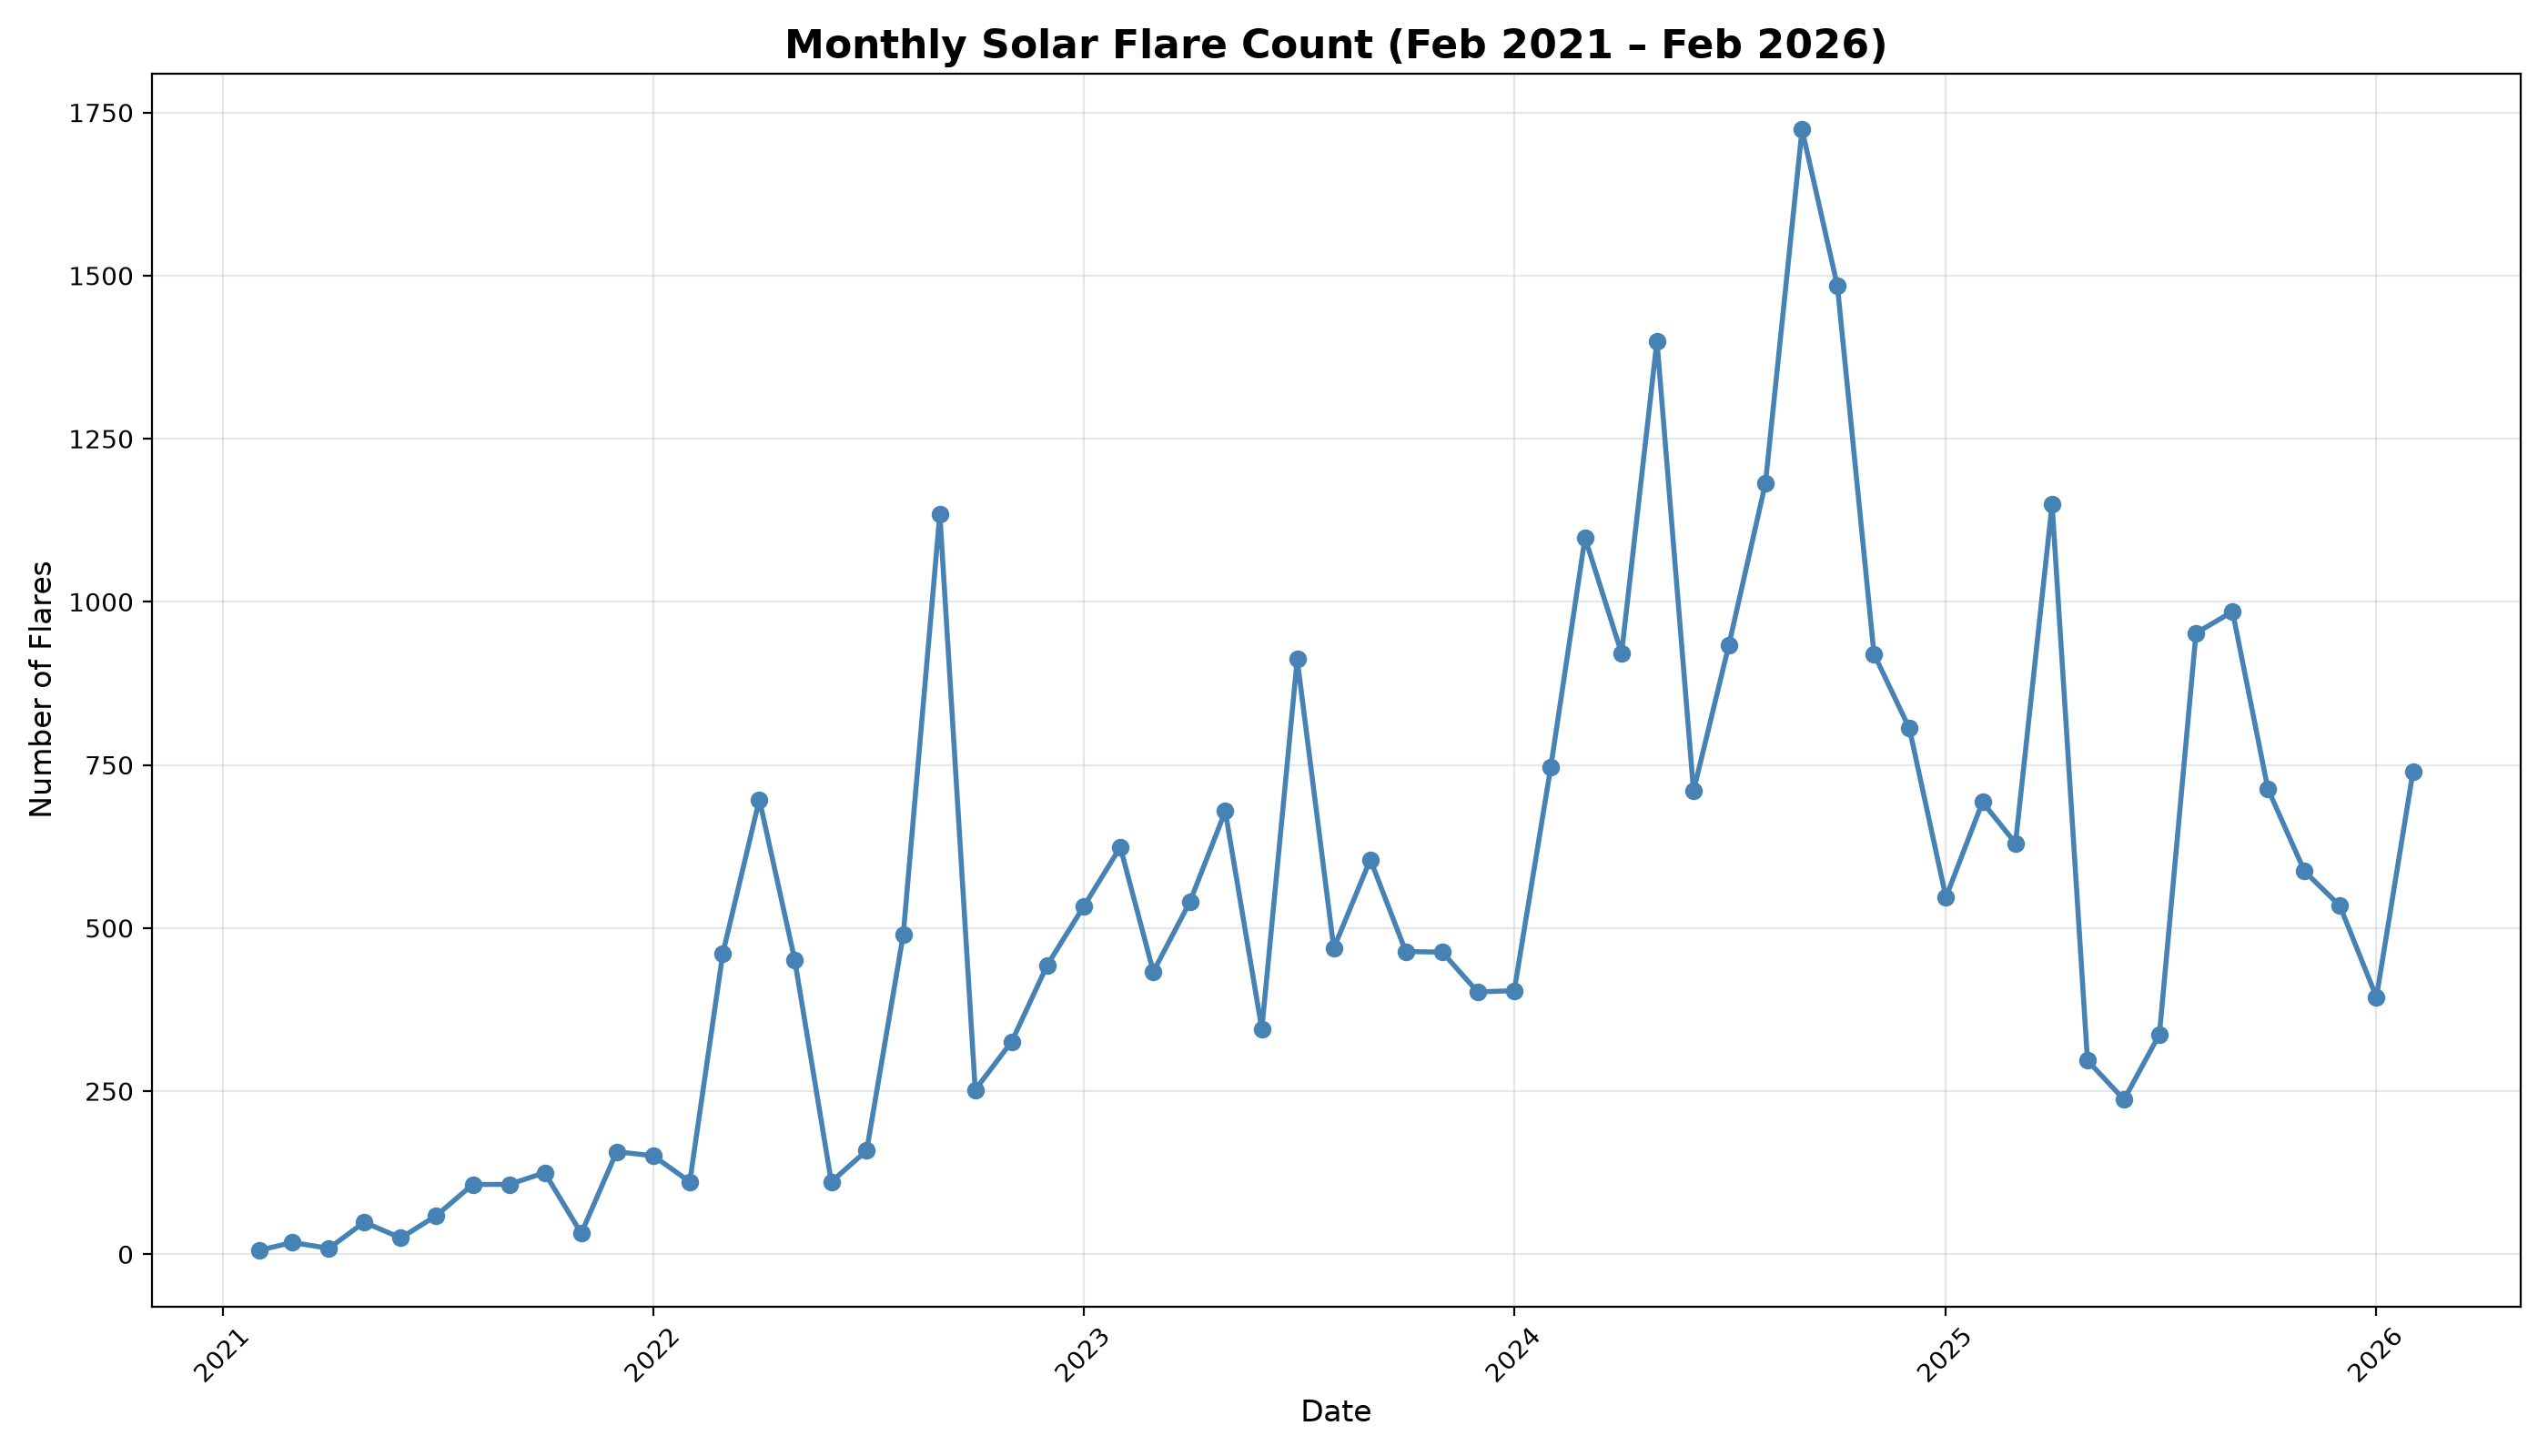
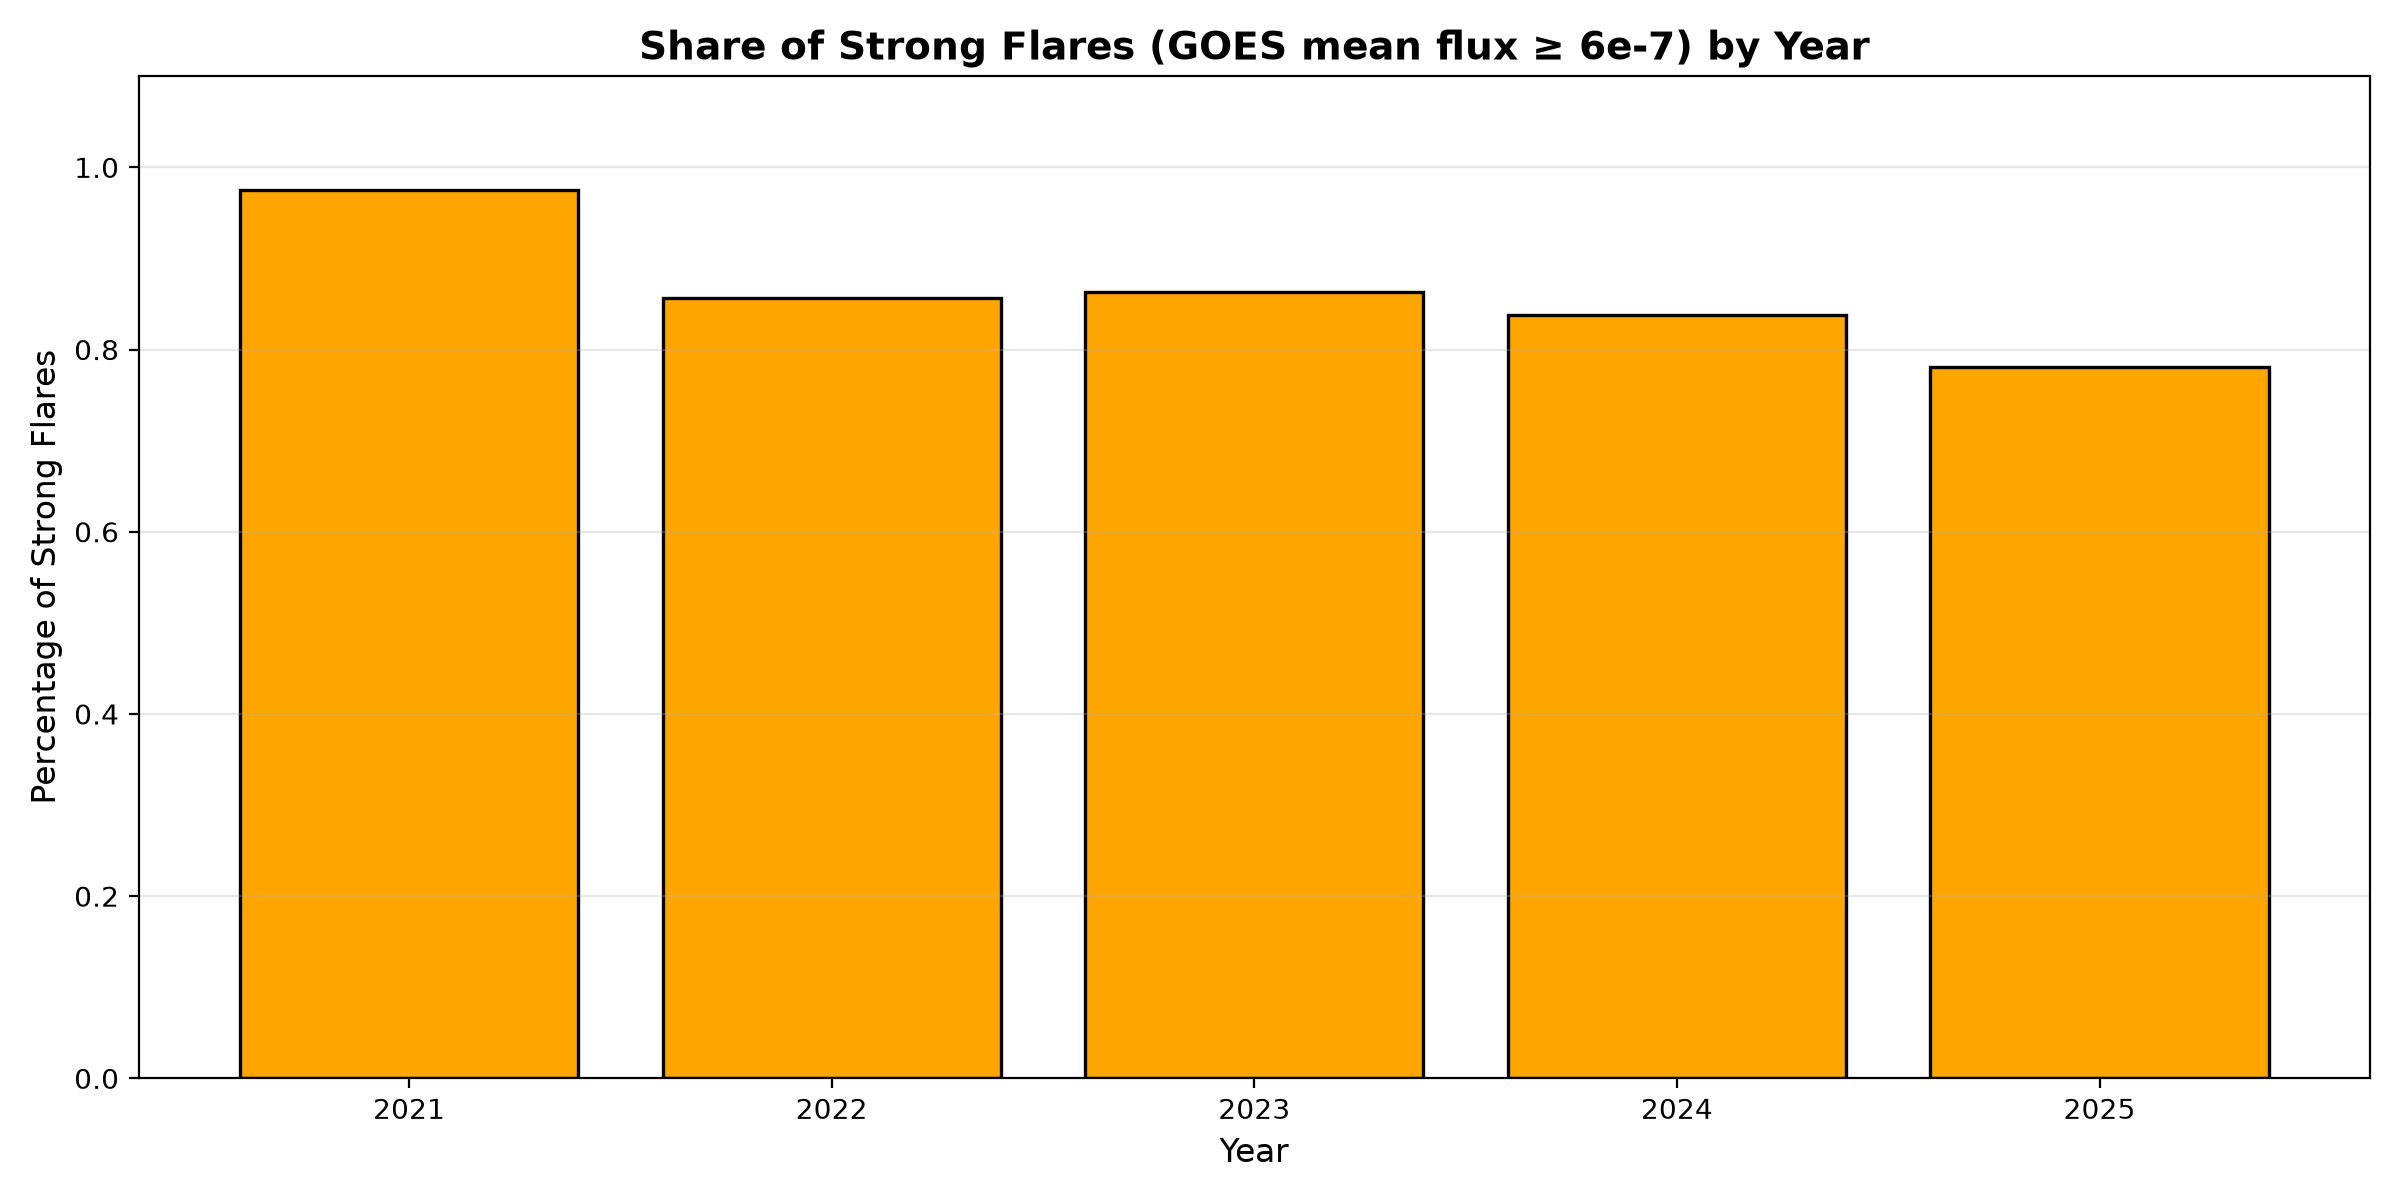
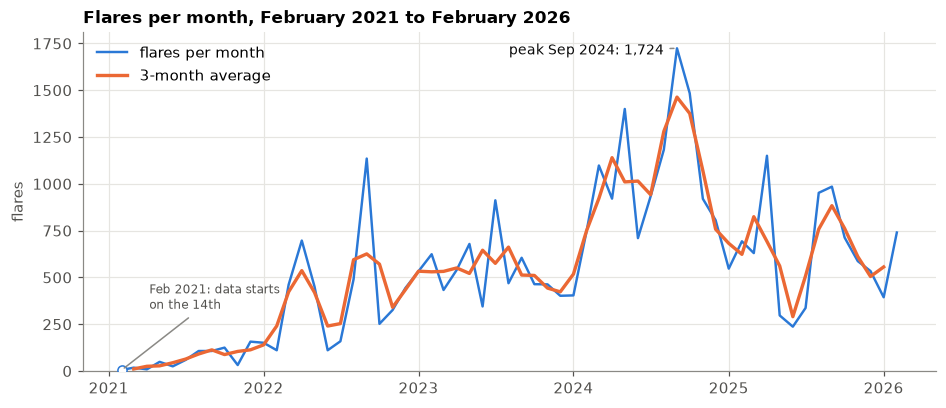
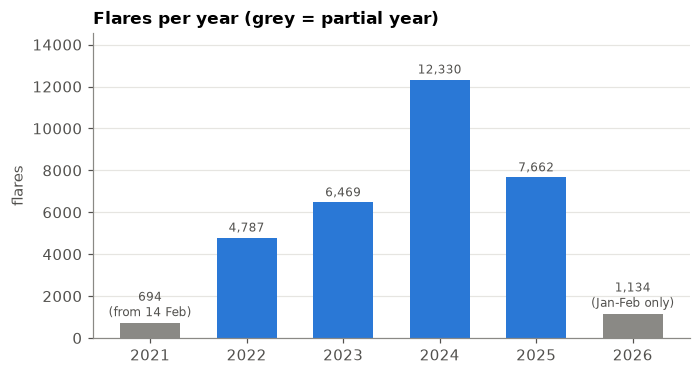
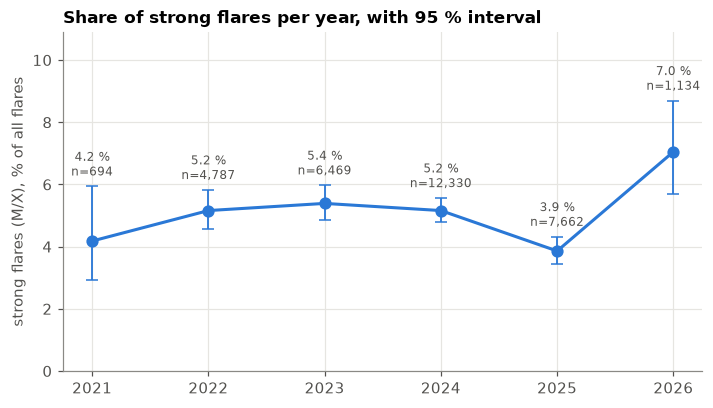
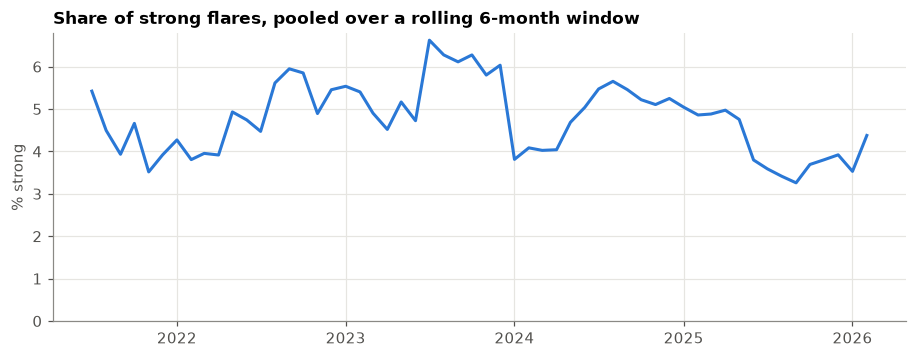
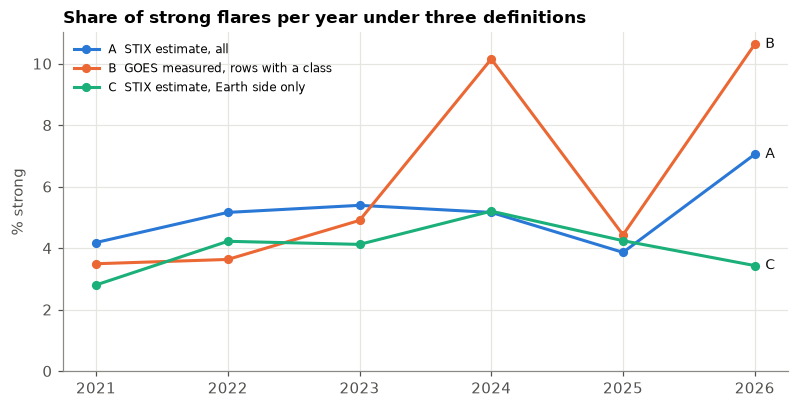

In [7]:
def figure(b64, caption):
    return (f'<figure style="margin:0 0 14px 0"><img src="data:image/png;base64,{b64}" style="width:100%">'
            f'<figcaption style="font-size:85%;color:#666">{html.escape(caption)}</figcaption></figure>')


model_figs = [figure(base64.b64encode(p.read_bytes()).decode(), p.name) for p in sorted((D / "outputs").glob("*.png"))]
ref_nb = json.loads((ROOT / "notebooks" / "EDA_Report.ipynb").read_text(encoding="utf-8"))
ref_figs = []
for c in ref_nb["cells"]:
    for o in c.get("outputs", []):
        png = o.get("data", {}).get("image/png")
        if c["cell_type"] == "code" and png:
            src = "".join(c["source"]).splitlines()
            ref_figs.append(figure("".join(png) if isinstance(png, list) else png, src[0].lstrip("# ")[:90] if src else ""))
display(HTML('<div style="display:grid;grid-template-columns:1fr 1fr;gap:20px;align-items:start">'
             f'<div><h4>Model: {len(model_figs)} plot(s)</h4>{"".join(model_figs) or "<p>no plot saved</p>"}</div>'
             f'<div><h4>Reference: EDA_Report</h4>{"".join(ref_figs) or "<p>EDA_Report has no saved plots</p>"}</div></div>'))

## 6. Report text
The text the model printed (before any `RESULTS_JSON` line). Numbers are marked
<span style="background:#d7f5dd">green</span> if they match a ground-truth value and
<span style="background:#fbd5d0">red</span> if not (same rule as `report_precision`; years, months and small counts are ignored).

In [8]:
TEXT = RQ["report_text"]


def highlight(text):
    out, last = [], 0
    for mt in re.finditer(r"(?<![\w.])\d[\d,']*(?:\.\d+)?", text):
        nums = numbers_in(mt.group())
        out.append(html.escape(text[last:mt.start()]))
        if nums:
            ok = any(abs(nums[0] - g) <= max(0.02 * abs(g), 0.1) for g in GT_NUMS)
            out.append(f'<span style="background:{"#d7f5dd" if ok else "#fbd5d0"}">{html.escape(mt.group())}</span>')
        else:
            out.append(html.escape(mt.group()))
        last = mt.end()
    out.append(html.escape(text[last:]))
    return "".join(out)


if "Report-Text fest im Code (nicht aus Ergebnissen erzeugt)" in RQ["flags"]:
    display(Markdown("**The report text is a fixed string in the code**: it was written before anything was computed."))
display(HTML('<div style="white-space:pre-wrap;border-left:3px solid #ccc;padding-left:10px;max-height:24em;overflow:auto">'
             + (highlight(TEXT) or "<i>no text was printed</i>") + "</div>"))

claims = text_claims(TEXT)
checked = RQ["details"]["correctness"]["text_facts"]
pd.DataFrame([{"fact": k, "text says": fmt(v), "ground truth": fmt(GT.get(KEYS[k])), "ok": mark(checked.get(k))}
              for k, v in claims.items()]).set_index("fact")

**The report text is a fixed string in the code**: it was written before anything was computed.

,text says,ground truth,ok
fact,,,
n_months,–,61,–
busiest_month,2021-02,2024-09,✗
busiest_month_count,[198.0],1724,✗
n_strong,–,1637,–
strong_share_increasing,True,False,✗


## 7. The same seed across the reflection levels
The baseline and every experiment built on it (`base` in the manifest). All levels start from the same frozen v1.

In [9]:
BASE = m.get("base") or EXP
family = [BASE] + sorted(e.name for e in EXP_DIR.iterdir()
                         if (e / "experiment.json").exists() and manifest(e.name).get("base") == BASE)
v1_code = read(version_dir(BASE, SEED, "v1"), "code.py")
rows = []
for exp in family:
    try:
        d = version_dir(exp, SEED)
    except (FileNotFoundError, IndexError):
        continue
    f, fn, rq = facts_for_dir(d), funnel_for_dir(d), report_quality_for_dir(d)
    r = json.loads(read(d, "result.json"))
    diff = [l for l in difflib.unified_diff(v1_code.splitlines(), read(d, "code.py").splitlines(), lineterm="", n=0)
            if l[:1] in "+-" and not l.startswith(("+++", "---"))]
    rows.append({"experiment": exp, "level": manifest(exp).get("level"), "version": d.name, "exit": r.get("exit_code"),
                 "error": r.get("error_category") or "", "depth": fn["depth"], "facts": f"{f['fact_score']:.0%}",
                 **{k: mark(f["checks"].get(k)) for k in KEYS}, "report": rq["overall"],
                 "lines changed vs v1": len(diff)})
pd.DataFrame(rows).set_index("experiment")

,level,version,exit,error,depth,facts,n_months,busiest_month,busiest_month_count,flares_per_year,n_strong,pct_strong_per_year,strong_share_increasing,report,lines changed vs v1
experiment,,,,,,,,,,,,,,,
E10_baseline_v3,baseline,v1,0,,7,71%,✓,✓,✓,✓,✗,✗,✓,0.702,0


### What the critic said and what it changed
For the selected run only (empty for a baseline). The critique is shortened; the full text is in `critique.md`.

In [10]:
critique = read(D, "critique.md")
if not critique:
    display(Markdown("_This is a baseline version: no critique._"))
else:
    display(Markdown("**Critique** (first 1500 characters):\n\n" + critique[:1500]))
    diff = list(difflib.unified_diff(v1_code.splitlines(), CODE.splitlines(), "v1/code.py", f"{D.name}/code.py", lineterm="", n=1))
    display(HTML("<b>Code changes v1 → " + D.name + "</b><pre style='max-height:30em;overflow:auto'>"
                 + html.escape("\n".join(diff[:200]) or "(no change)") + "</pre>"))

_This is a baseline version: no critique._